# Complex-Time Anharmonic Propagator — corrected multi-thimble MU

This notebook runs one selected coupling at a time at $N=16$ and fixes the nearly
$\lambda$-independent result produced by the old one-thimble model.  Set `MU_LAMBDA`
externally to keep each requested run and its outputs independent.

The old calculation learned only the thimble through the zero saddle.  For the hard
quartic oscillator there is also a lowest-action nonzero zero-endpoint saddle and its
parity partner.  With every tangent given the canonical `det(V)=+1` orientation, the
physical real integration cycle decomposes as

$$K_{\rm physical}=K_{0}+K_{+}+K_{-}=K_{0}+2K_{\rm bounce}.$$

Each contribution is learned independently by a saddle-anchored rank-16 neural contour.
The implementation also incorporates the definite corrections from
`Re__Complex_Time_Code_`:

- `complex128` action, Jacobian and weights;
- the correct $A^{-1}C$ low-rank determinant formula for `x = z @ A.T`;
- a full finite-difference Jacobian preflight;
- comparison to the deterministic **same-$N$** anharmonic reference, not the $\lambda=0$
  Mehler kernel;
- stable `log|W|` plus circular-phase training, avoiding an angle branch cut.

Default settings (`1000` epochs per saddle, `80,000` MC samples) reproduce the $N=16$
reference in about 1–2 minutes on this CPU.

In [1]:
from __future__ import annotations

import csv
import json
import math
import os
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg
import torch
import torch.nn as nn
from scipy.optimize import root

%matplotlib inline

torch.set_default_dtype(torch.float64)

# Physics: only the requested lambda=0.7 run.
N = 16
D = N - 1
T = 1.0
ETA = 0.05
MASS = 1.0
OMEGA = 1.0
# Override from a terminal/runner with MU_LAMBDA=2.4 or MU_LAMBDA=3.0.
LAMBDA = 4
A_C = (T - 1j * ETA) / N
X_I = X_F = 0.0 

# Fastest configuration tested to remain statistically meaningful.
RANK = 16
EPOCHS = 1_000
BATCH = 512
LEARNING_RATE = 1.0e-3
N_MC = 80_000
MC_CHUNK = 5_000
SEED = 52
LOG_EVERY = 250

# Set True only for a syntax check; its numbers are not physics results.
QUICK_TEST = False
if QUICK_TEST:
    EPOCHS, BATCH, N_MC, MC_CHUNK, LOG_EVERY = 5, 32, 1_000, 500, 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
run_dir = Path("runs") / f"{stamp}_MU_multithimble_lambda{LAMBDA:g}_N{N}"
run_dir.mkdir(parents=True, exist_ok=True)

print(f"device={DEVICE}; dtype=float64/complex128")
print(f"N={N}, D={D}, T_c={T}-{ETA}i, lambda={LAMBDA}")
print(f"rank={RANK}, epochs={EPOCHS} per saddle, batch={BATCH}, N_mc={N_MC}")
print(f"run directory: {run_dir.resolve()}")

device=cpu; dtype=float64/complex128
N=16, D=15, T_c=1.0-0.05i, lambda=4
rank=16, epochs=1000 per saddle, batch=512, N_mc=80000
run directory: C:\xampp1\Quantum\runs\20260915_144540_MU_multithimble_lambda4_N16


## 1. Lattice action and stationary points

For zero endpoints, the $D=N-1$ complex interior coordinates have action

$$S[x]=\frac{m}{2a_c}\sum_{k=0}^{N-1}(x_{k+1}-x_k)^2
-\frac{a_cm\omega^2}{2}\sum_{k=1}^{N-1}x_k^2
-\frac{a_c\lambda}{4}\sum_{k=1}^{N-1}x_k^4,$$

with $a_c=(T-i\eta)/N$ and weight $e^{iS}$.  Unlike the harmonic oscillator, the hard
quartic oscillator has nonzero zero-to-zero solutions even when $T<\pi/\omega$: increasing
amplitude raises its frequency.  The previous notebook incorrectly retained only $x=0$.

In [2]:
def action_np(x: np.ndarray) -> complex:
    """Discretised complex-time action for one path."""
    padded = np.r_[0.0 + 0.0j, x, 0.0 + 0.0j]
    dx = np.diff(padded)
    return (
        MASS / (2.0 * A_C) * np.sum(dx**2)
        - A_C * MASS * OMEGA**2 / 2.0 * np.sum(x**2)
        - A_C * LAMBDA / 4.0 * np.sum(x**4)
    )


def gradient_np(x: np.ndarray) -> np.ndarray:
    """Holomorphic gradient dS/dx at the interior lattice sites."""
    padded = np.r_[0.0 + 0.0j, x, 0.0 + 0.0j]
    return (
        (MASS / A_C) * (2.0 * x - padded[:-2] - padded[2:])
        - A_C * MASS * OMEGA**2 * x
        - A_C * LAMBDA * x**3
    )


def hessian_np(x: np.ndarray) -> np.ndarray:
    """Complex-symmetric Hessian d^2S/dx_j dx_k at a saddle."""
    hessian = np.zeros((D, D), dtype=np.complex128)
    np.fill_diagonal(
        hessian,
        2.0 * MASS / A_C
        - A_C * MASS * OMEGA**2
        - 3.0 * A_C * LAMBDA * x**2,
    )
    np.fill_diagonal(hessian[1:], -MASS / A_C)
    np.fill_diagonal(hessian[:, 1:], -MASS / A_C)
    return hessian


def packed_gradient(y: np.ndarray) -> np.ndarray:
    x = y[:D] + 1j * y[D:]
    grad = gradient_np(x)
    return np.r_[grad.real, grad.imag]


def action_torch(x: torch.Tensor) -> torch.Tensor:
    """Batch action accumulated entirely in complex128."""
    x = x.to(torch.complex128)
    zero = torch.zeros((x.shape[0], 1), dtype=torch.complex128, device=x.device)
    padded = torch.cat((zero, x, zero), dim=1)
    dx = padded[:, 1:] - padded[:, :-1]
    a = torch.as_tensor(A_C, dtype=torch.complex128, device=x.device)
    return (
        MASS / (2.0 * a) * torch.sum(dx**2, dim=1)
        - a * MASS * OMEGA**2 / 2.0 * torch.sum(x**2, dim=1)
        - a * LAMBDA / 4.0 * torch.sum(x**4, dim=1)
    )

## 2. Locate the missing bounce and construct local thimble tangents

The first nonzero saddle is found from sine-wave initial guesses and refined against the
full complex lattice equations.  Its parity partner $-x_{\rm b}$ has exactly the same action
and Hessian because the potential is even.

At each saddle, a complex-orthogonal eigendecomposition builds $A_\sigma$ satisfying

$$A_\sigma^T H_\sigma A_\sigma=iI,$$

so $x=x_\sigma+A_\sigma z$ starts on the exact local steepest-descent tangent.  The saddle and
this linear map remain fixed during training, preventing either network from drifting into
the zero saddle or flipping orientation.

In [3]:
def first_bounce() -> np.ndarray:
    """Find the lowest-action nonzero zero-endpoint saddle.

    A hard quartic oscillator has amplitude-dependent frequency, so this solution exists
    even though T < pi/omega.  Several amplitudes are tried to avoid accepting x=0.
    """
    sites = np.arange(1, N)
    shape = np.sin(np.pi * sites / N)
    candidates = []
    for amplitude in np.linspace(2.0, 7.0, 11):
        guess = np.r_[amplitude * shape, np.zeros(D)]
        solved = root(packed_gradient, guess, method="lm", options={"maxiter": 5_000})
        x = solved.x[:D] + 1j * solved.x[D:]
        residual = np.max(np.abs(gradient_np(x)))
        if residual < 1e-8 and np.max(np.abs(x)) > 1e-3:
            if not any(np.max(np.abs(x - old)) < 1e-6 for old in candidates):
                candidates.append(x)
    if not candidates:
        raise RuntimeError("Could not find the first nonzero saddle")
    return min(candidates, key=lambda x: abs(action_np(x)))


def tangent_map(hessian: np.ndarray) -> np.ndarray:
    """Return canonically oriented A with A.T @ H @ A = iI."""
    values, vectors = np.linalg.eig(hessian)
    for k in range(D):
        vectors[:, k] /= np.sqrt(vectors[:, k].T @ vectors[:, k])

    # Complex orthogonality implies det(V)=+/-1.  Fix +1 so every saddle uses
    # the same orientation inherited from the real coordinate basis; otherwise
    # a LAPACK eigenvector sign arbitrarily changes K_sigma -> -K_sigma.
    if np.linalg.det(vectors).real < 0.0:
        vectors[:, 0] *= -1.0

    orthogonal_error = np.max(np.abs(vectors.T @ vectors - np.eye(D)))
    orientation_error = abs(np.linalg.det(vectors) - 1.0)
    tangent = vectors @ np.diag(np.sqrt(1j / values))
    residual = np.max(np.abs(tangent.T @ hessian @ tangent - 1j * np.eye(D)))
    if orthogonal_error > 1e-8 or orientation_error > 1e-8 or residual > 1e-8:
        raise RuntimeError(
            "Bad saddle tangent: "
            f"orthogonal={orthogonal_error}, orientation={orientation_error}, "
            f"congruence={residual}"
        )
    return tangent


def fixed_n_reference(basis_size: int = 300) -> complex:
    """Independent deterministic evaluation of this exact N-slice path integral."""
    nb = int(basis_size)
    lowering = np.zeros((nb, nb), dtype=np.float64)
    idx = np.arange(1, nb)
    lowering[idx - 1, idx] = np.sqrt(idx)
    x_op = (lowering + lowering.T) / np.sqrt(2.0)
    p_op = (lowering - lowering.T) / (1j * np.sqrt(2.0))
    x2 = x_op @ x_op

    kinetic = p_op @ p_op / (2.0 * MASS)
    ep, up = scipy.linalg.eigh(kinetic)
    free_step = (up * np.exp(-1j * A_C * ep)) @ up.conj().T

    potential = MASS * OMEGA**2 * x2 / 2.0 + LAMBDA * (x2 @ x2) / 4.0
    ev, uv = scipy.linalg.eigh(potential)
    potential_step = (uv * np.exp(-1j * A_C * ev)) @ uv.conj().T

    position_zero = np.zeros(nb, dtype=np.float64)
    for n in range(0, nb, 2):
        q = n // 2
        position_zero[n] = (-1.0)**q * math.exp(
            0.5 * math.lgamma(2 * q + 1) - q * math.log(2.0)
            - math.lgamma(q + 1) - 0.25 * math.log(np.pi)
        )

    evolution = free_step.copy()
    for _ in range(N - 1):
        evolution = evolution @ potential_step @ free_step
    return complex(position_zero @ evolution @ position_zero)


def gaussian_saddle_estimate(saddle: np.ndarray) -> complex:
    """Quadratic saddle estimate; used only as a decomposition diagnostic."""
    hessian = hessian_np(saddle)
    norm = (MASS / (2.0 * np.pi * 1j * A_C)) ** (N / 2)
    return complex(
        norm * np.exp(1j * action_np(saddle))
        * (2.0 * np.pi * 1j) ** (D / 2) / np.sqrt(np.linalg.det(hessian))
    )

## 3. Saddle-anchored neural contour

For each saddle $x_\sigma$ the learned map is

$$x(z)=x_\sigma+A_\sigma z+C\tanh\!\left(W_2\tanh(W_1z)\right).$$

There are no neural biases, so $g(0)=0$ and the contour always passes through its assigned
saddle.  $A_\sigma$ and $x_\sigma$ are buffers rather than trainable parameters.  Only the
rank-16 nonlinear correction learns.

The full Jacobian is

$$J=A_\sigma+C D_2W_2D_1W_1.$$

For `x = z @ A.T`, Sylvester's identity requires **`solve(A, C)`**.  The old notebook used
`solve(A.T, C)`, i.e. $A^{-T}C$, which is the transpose bug identified in
`Re__Complex_Time_Code_/note_for_tom.pdf`.

In [4]:
class SaddleFlow(nn.Module):
    """Fixed saddle/tangent plus a saddle-anchored low-rank correction."""

    def __init__(self, saddle: np.ndarray, tangent: np.ndarray, seed: int):
        super().__init__()
        torch.manual_seed(seed)
        self.register_buffer(
            "saddle", torch.tensor(saddle, dtype=torch.complex128, device=DEVICE)
        )
        self.register_buffer(
            "A", torch.tensor(tangent, dtype=torch.complex128, device=DEVICE)
        )
        self.W1 = nn.Parameter(torch.randn(RANK, D, device=DEVICE) / math.sqrt(D))
        qmat, _ = torch.linalg.qr(torch.randn(RANK, RANK, device=DEVICE))
        self.W2 = nn.Parameter(qmat)
        # Tiny rather than exactly zero so every layer receives a gradient on step one.
        self.C_real = nn.Parameter(1e-5 * torch.randn(D, RANK, device=DEVICE))
        self.C_imag = nn.Parameter(1e-5 * torch.randn(D, RANK, device=DEVICE))

    def C(self) -> torch.Tensor:
        return self.C_real.to(torch.complex128) + 1j * self.C_imag.to(torch.complex128)

    def forward(self, z: torch.Tensor, return_cache: bool = False):
        z = z.to(dtype=torch.float64, device=DEVICE)
        a1 = torch.tanh(z @ self.W1.T)
        a2 = torch.tanh(a1 @ self.W2.T)
        x = (
            z.to(torch.complex128) @ self.A.T
            + self.saddle
            + a2.to(torch.complex128) @ self.C().T
        )
        return (x, (a1, a2)) if return_cache else x

    def full_jacobian(self, a1: torch.Tensor, a2: torch.Tensor) -> torch.Tensor:
        """Exact batch Jacobian A + C D2 W2 D1 W1, including all cross terms."""
        d1 = 1.0 - a1**2
        d2 = 1.0 - a2**2
        h1 = d1.unsqueeze(-1) * self.W1.unsqueeze(0)
        h2 = torch.matmul(self.W2.unsqueeze(0), h1)
        dh_dz = d2.unsqueeze(-1) * h2
        correction = torch.matmul(self.C().unsqueeze(0), dh_dz.to(torch.complex128))
        return self.A.unsqueeze(0) + correction

    def determinant_parts(self, a1: torch.Tensor, a2: torch.Tensor):
        """Return log|det J| and det(J)/|det(J)| via the corrected low-rank formula."""
        sign_a, logabs_a = torch.linalg.slogdet(self.A)
        # Correct for forward x = z @ A.T.  This is A^{-1}C, not A^{-T}C.
        k_mat = self.W1.to(torch.complex128) @ torch.linalg.solve(self.A, self.C())
        d1 = (1.0 - a1**2).to(torch.complex128)
        d2 = (1.0 - a2**2).to(torch.complex128)
        m1 = d1.unsqueeze(-1) * k_mat.unsqueeze(0)
        m2 = torch.matmul(self.W2.to(torch.complex128).unsqueeze(0), m1)
        correction = (
            torch.eye(RANK, dtype=torch.complex128, device=DEVICE).unsqueeze(0)
            + d2.unsqueeze(-1) * m2
        )
        sign_c, logabs_c = torch.linalg.slogdet(correction)
        return logabs_a + logabs_c, sign_a * sign_c

## 4. Preflight checks

Before training, the notebook verifies:

1. the bounce residual $\|\partial S/\partial x\|_\infty$;
2. parity: $S[x_b]=S[-x_b]$ and $H[x_b]=H[-x_b]$;
3. $A_\sigma^T H_\sigma A_\sigma=iI$;
4. the analytic full Jacobian against central finite differences;
5. the corrected low-rank determinant against `det(full_jacobian)`.

The quadratic saddle estimates provide an independent scale check.  Already at Gaussian
order, subtracting the bounce pair shifts the zero-saddle answer in precisely the direction
required by the deterministic reference.

In [5]:
def validate_saddles_and_jacobian(trivial: np.ndarray, bounce: np.ndarray) -> None:
    residual = np.max(np.abs(gradient_np(bounce)))
    parity_action = abs(action_np(bounce) - action_np(-bounce))
    parity_hessian = np.max(np.abs(hessian_np(bounce) - hessian_np(-bounce)))
    if residual > 1e-8 or parity_action > 1e-10 or parity_hessian > 1e-10:
        raise RuntimeError("Saddle or parity preflight failed")

    tangent = tangent_map(hessian_np(bounce))
    model = SaddleFlow(bounce, tangent, SEED + 999)
    # Make the nonlinear correction large enough that the check tests it, not only A.
    with torch.no_grad():
        model.C_real.normal_(std=0.03)
        model.C_imag.normal_(std=0.03)

    z = torch.randn(3, D, dtype=torch.float64, device=DEVICE)
    x, (a1, a2) = model(z, return_cache=True)
    jacobian = model.full_jacobian(a1, a2)
    eps = 1e-6
    jacobian_fd = torch.empty_like(jacobian)
    with torch.no_grad():
        for k in range(D):
            dz = torch.zeros_like(z)
            dz[:, k] = eps
            jacobian_fd[:, :, k] = (model(z + dz) - model(z - dz)) / (2.0 * eps)
    fd_error = float(torch.max(torch.abs(jacobian - jacobian_fd)).cpu())

    logabs, sign = model.determinant_parts(a1, a2)
    det_low_rank = torch.exp(logabs) * sign
    det_full = torch.linalg.det(jacobian)
    determinant_error = float(torch.max(torch.abs(det_low_rank - det_full)).cpu())
    determinant_relative = determinant_error / max(
        float(torch.max(torch.abs(det_full)).cpu()), 1e-300
    )

    print(f"bounce residual              : {residual:.3e}")
    print(f"parity action/Hessian errors : {parity_action:.3e}, {parity_hessian:.3e}")
    print(f"full Jacobian FD error       : {fd_error:.3e}")
    print(f"low-rank determinant rel err : {determinant_relative:.3e}")
    if fd_error > 3e-7 or determinant_relative > 3e-8:
        raise RuntimeError("Corrected Jacobian preflight failed")
    print("All saddle and Jacobian preflight checks PASSED")

## 5. Branch-safe training and complex importance weights

For standard-normal $z$, write the weight without taking a complex logarithm:

$$\log|W|=-\operatorname{Im}S+\log|\det J|-\log P(z),\qquad
u_W=e^{i\operatorname{Re}S}\frac{\det J}{|\det J|}.$$

The objective is

$$\operatorname{Var}[\log|W|]+1-|\langle\nu_W\rangle|^2.$$

The second term is circular phase variance; unlike `Var(Im(log W))`, it has no artificial
branch cut at $\pm\pi$.  Estimation retains the required
$W=e^{iS}\det J/P$ and the original complex-time normalization.  Five independent MC
blocks expose sampling instability.

In [6]:
LOG_2PI = math.log(2.0 * math.pi)


def weight_parts(model: SaddleFlow, z: torch.Tensor):
    """Branch-safe representation of exp(iS) det(J) / P(z)."""
    x, (a1, a2) = model(z, return_cache=True)
    action = action_torch(x)
    logabs_j, sign_j = model.determinant_parts(a1, a2)
    log_p = -0.5 * torch.sum(z**2, dim=1) - 0.5 * D * LOG_2PI
    logabs_w = -action.imag + logabs_j - log_p
    phase_w = torch.exp(1j * action.real) * sign_j
    return logabs_w, phase_w


def train_thimble(label: str, saddle: np.ndarray, seed: int):
    tangent = tangent_map(hessian_np(saddle))
    model = SaddleFlow(saddle, tangent, seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=EPOCHS, eta_min=LEARNING_RATE * 0.05
    )
    history = {"total": [], "logmag": [], "phase": []}
    started = time.time()

    for epoch in range(EPOCHS):
        optimizer.zero_grad(set_to_none=True)
        z = torch.randn(BATCH, D, dtype=torch.float64, device=DEVICE)
        logabs_w, phase_w = weight_parts(model, z)
        logmag_variance = torch.var(logabs_w, unbiased=False)
        circular_phase = 1.0 - torch.abs(torch.mean(phase_w))**2
        loss = logmag_variance + circular_phase
        if not torch.isfinite(loss):
            raise FloatingPointError(f"{label}: nonfinite loss at epoch {epoch + 1}")
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        optimizer.step()
        scheduler.step()

        history["total"].append(float(loss.detach().cpu()))
        history["logmag"].append(float(logmag_variance.detach().cpu()))
        history["phase"].append(float(circular_phase.detach().cpu()))
        if epoch == 0 or (epoch + 1) % LOG_EVERY == 0 or epoch + 1 == EPOCHS:
            print(
                f"{label:8s} epoch {epoch+1:4d}/{EPOCHS}: "
                f"loss={history['total'][-1]:.3e}, "
                f"logmag={history['logmag'][-1]:.3e}, "
                f"phase={history['phase'][-1]:.3e}, "
                f"elapsed={time.time()-started:.0f}s",
                flush=True,
            )
    return model, history, time.time() - started


def estimate_thimble(model: SaddleFlow, seed: int):
    """Chunked complex128 MC estimate with five independent stability blocks."""
    torch.manual_seed(seed + 100_000)
    logs, phases = [], []
    remaining = N_MC
    model.eval()
    while remaining:
        count = min(MC_CHUNK, remaining)
        z = torch.randn(count, D, dtype=torch.float64, device=DEVICE)
        with torch.no_grad():
            logabs, phase = weight_parts(model, z)
        logs.append(logabs.cpu())
        phases.append(phase.cpu())
        remaining -= count

    logabs = torch.cat(logs)
    phase = torch.cat(phases)
    shift = torch.max(logabs)
    shifted = torch.exp(logabs - shift) * phase
    norm = (MASS / (2.0 * np.pi * 1j * A_C)) ** (N / 2)
    scale = norm * math.exp(float(shift))
    estimate = complex(scale * torch.mean(shifted).numpy())

    centered = shifted - torch.mean(shifted)
    stderr = abs(scale) * math.sqrt(float(torch.mean(torch.abs(centered)**2)) / N_MC)
    ess = float(
        torch.abs(torch.mean(shifted))**2 / torch.mean(torch.abs(shifted)**2)
    )
    blocks = [
        complex(scale * torch.mean(block).numpy())
        for block in torch.tensor_split(shifted, 5)
    ]
    block_scatter = float(np.std(np.asarray(blocks, dtype=np.complex128)))
    return estimate, stderr, ess, block_scatter, blocks

## 6. Find and validate the two required saddle sectors

The deterministic basis calculation evaluates the identical $N=16$ Trotterized path
integral and supplies the acceptance target.  It is independent of the ML contour and MC
estimator.

For the discovered saddle, this cell also prints its action and the quadratic estimates.
The higher-action bounce families are exponentially suppressed for the selected couplings;
the first parity pair is the missing contribution visible at the precision requested here.
The canonical tangent orientation makes each real-cycle intersection coefficient `+1`; the
sign of each saddle contribution is then carried by its Jacobian.

In [7]:
trivial_saddle = np.zeros(D, dtype=np.complex128)
bounce_saddle = first_bounce()
reference = fixed_n_reference()

validate_saddles_and_jacobian(trivial_saddle, bounce_saddle)

trivial_gaussian = gaussian_saddle_estimate(trivial_saddle)
bounce_gaussian = gaussian_saddle_estimate(bounce_saddle)
gaussian_combined = trivial_gaussian + 2.0 * bounce_gaussian

print("\nSaddle decomposition diagnostics")
print(f"trivial action             : {action_np(trivial_saddle):+.10f}")
print(f"bounce max|x|              : {np.max(np.abs(bounce_saddle)):.6f}")
print(f"bounce action              : {action_np(bounce_saddle):+.10f}")
print(f"bounce exp(-Im S)          : {np.exp(-action_np(bounce_saddle).imag):.4e}")
print(f"Gaussian K_trivial         : {trivial_gaussian:+.10f}")
print(f"Gaussian K_bounce          : {bounce_gaussian:+.10f}")
print(f"Gaussian K0 + 2*Kbounce    : {gaussian_combined:+.10f}")
print(f"N={N} deterministic target : {reference:+.10f}")

# Rounded N=16 rows supplied in Re__Complex_Time_Code_/lattice_targets_for_tom.csv.
supplied_n16_targets = {
    0.7: 0.269 - 0.282j,
    2.4: -0.108 - 0.139j,
}
reference_from_supplied_csv = supplied_n16_targets.get(round(LAMBDA, 10))
if reference_from_supplied_csv is None:
    print("supplied CSV               : no lambda=3 row; using deterministic same-N target")
else:
    print(f"supplied CSV (rounded)      : {reference_from_supplied_csv:+.10f}")

bounce residual              : 4.230e-15
parity action/Hessian errors : 0.000e+00, 0.000e+00
full Jacobian FD error       : 2.180e-10
low-rank determinant rel err : 1.879e-15
All saddle and Jacobian preflight checks PASSED

Saddle decomposition diagnostics
trivial action             : +0.0000000000+0.0000000000j
bounce max|x|              : 1.749796
bounce action              : +3.1097967373+0.5407505406j
bounce exp(-Im S)          : 5.8231e-01
Gaussian K_trivial         : +0.3120526023-0.3021870627j
Gaussian K_bounce          : -0.2379930623-0.2337454501j
Gaussian K0 + 2*Kbounce    : -0.1639335223-0.7696779630j
N=16 deterministic target : +0.8243744616+0.1842153864j
supplied CSV               : no lambda=3 row; using deterministic same-N target


## 7. Train the zero and bounce thimbles, then combine them

Only two networks are trained for the selected value of $\lambda$:

- `trivial`: the thimble through $x=0$, coefficient $+1$;
- `bounce`: the thimble through the first positive bounce.  Parity gives an equal negative
  bounce saddle.  Both lie on the real stationary cycle and have intersection coefficient
  $+1$, hence total coefficient $+2$ in the canonical tangent orientation.

The old notebook reported `K_trivial` as if it were the full answer.  This cell reports both
that baseline and the physical-cycle sum.

In [8]:
trained = {}
for offset, (label, saddle) in enumerate(
    (("trivial", trivial_saddle), ("bounce", bounce_saddle))
):
    print("\n" + "=" * 84)
    print(f"Training {label} thimble at lambda={LAMBDA}")
    print("=" * 84, flush=True)
    model, history, seconds = train_thimble(label, saddle, SEED + offset)
    estimate, stderr, ess, block_scatter, blocks = estimate_thimble(model, SEED + offset)
    trained[label] = {
        "model": model,
        "history": history,
        "seconds": seconds,
        "K": estimate,
        "stderr": stderr,
        "ESS": ess,
        "block_scatter": block_scatter,
        "blocks": blocks,
        "saddle": saddle,
        "seed": SEED + offset,
    }
    print(f"K_{label}={estimate:+.10f}")
    print(f"stderr={stderr:.3e}, ESS/N={ess:.6f}, block scatter={block_scatter:.3e}")
    for block_index, block in enumerate(blocks, start=1):
        print(f"  block {block_index}: {block:+.10f}")

K_trivial = trained["trivial"]["K"]
K_bounce = trained["bounce"]["K"]
K_combined = K_trivial + 2.0 * K_bounce
single_thimble_error = abs(K_trivial - reference) / abs(reference)
combined_error = abs(K_combined - reference) / abs(reference)
combined_stderr = math.sqrt(
    trained["trivial"]["stderr"]**2 + 4.0 * trained["bounce"]["stderr"]**2
)

print("\n" + "#" * 84)
print("PHYSICAL-CYCLE RESULT")
print("#" * 84)
print(f"K_trivial  = {K_trivial:+.10f}")
print(f"K_bounce   = {K_bounce:+.10f}  (one member of the parity pair)")
print(f"K_physical = K_trivial + 2*K_bounce = {K_combined:+.10f}")
print(f"K_reference= {reference:+.10f}")
print(f"old one-thimble error : {100*single_thimble_error:.3f}%")
print(f"corrected error       : {100*combined_error:.3f}%")
print(f"combined MC stderr    : {combined_stderr:.3e}")


Training trivial thimble at lambda=4


c:\Users\tomqu\Documents\MLandPython\envs\helios_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


trivial  epoch    1/1000: loss=3.595e-02, logmag=2.286e-03, phase=3.366e-02, elapsed=0s
trivial  epoch  250/1000: loss=1.432e-02, logmag=8.161e-04, phase=1.351e-02, elapsed=7s
trivial  epoch  500/1000: loss=9.047e-03, logmag=9.742e-04, phase=8.073e-03, elapsed=13s
trivial  epoch  750/1000: loss=6.874e-03, logmag=7.855e-04, phase=6.089e-03, elapsed=22s
trivial  epoch 1000/1000: loss=1.209e-02, logmag=1.124e-03, phase=1.096e-02, elapsed=46s
K_trivial=+0.3406518045-0.2638192423j
stderr=1.485e-04, ESS/N=0.990584, block scatter=1.473e-04
  block 1: +0.3406807447-0.2638949183j
  block 2: +0.3406149650-0.2636706283j
  block 3: +0.3405857159-0.2640137055j
  block 4: +0.3406314928-0.2638575794j
  block 5: +0.3407461041-0.2636593802j

Training bounce thimble at lambda=4
bounce   epoch    1/1000: loss=1.859e-01, logmag=9.309e-02, phase=9.279e-02, elapsed=0s
bounce   epoch  250/1000: loss=9.757e-02, logmag=5.248e-02, phase=4.510e-02, elapsed=9s
bounce   epoch  500/1000: loss=8.312e-02, logmag=4.22

## 8. Save checkpoints, CSV, JSON, report, and loss curves

All numerical values are written immediately into the timestamped run directory.  The CSV
contains both individual thimble contributions and the corrected physical sum, making it
impossible to confuse the old zero-saddle result with the propagator.

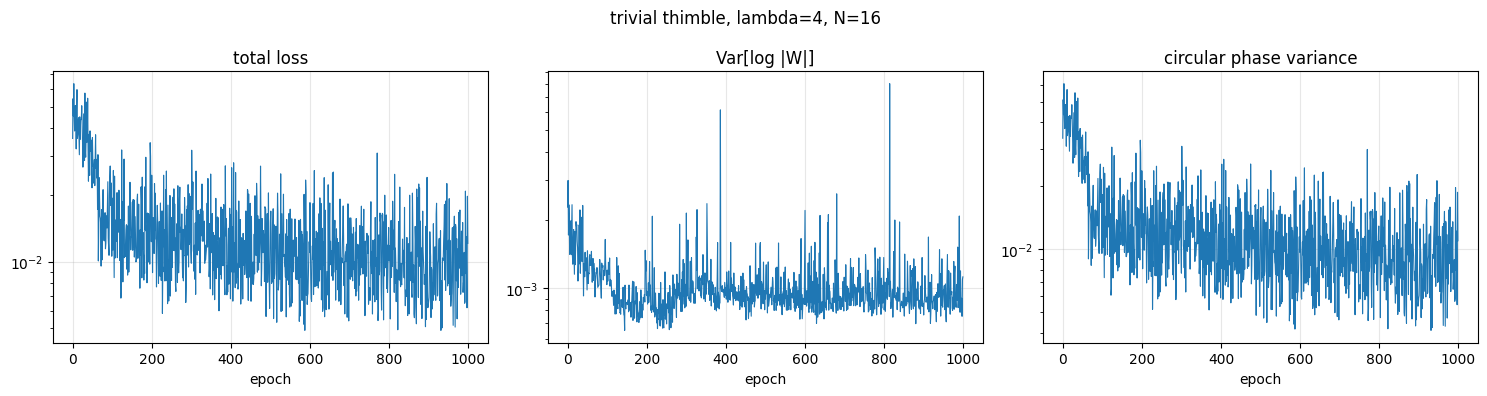

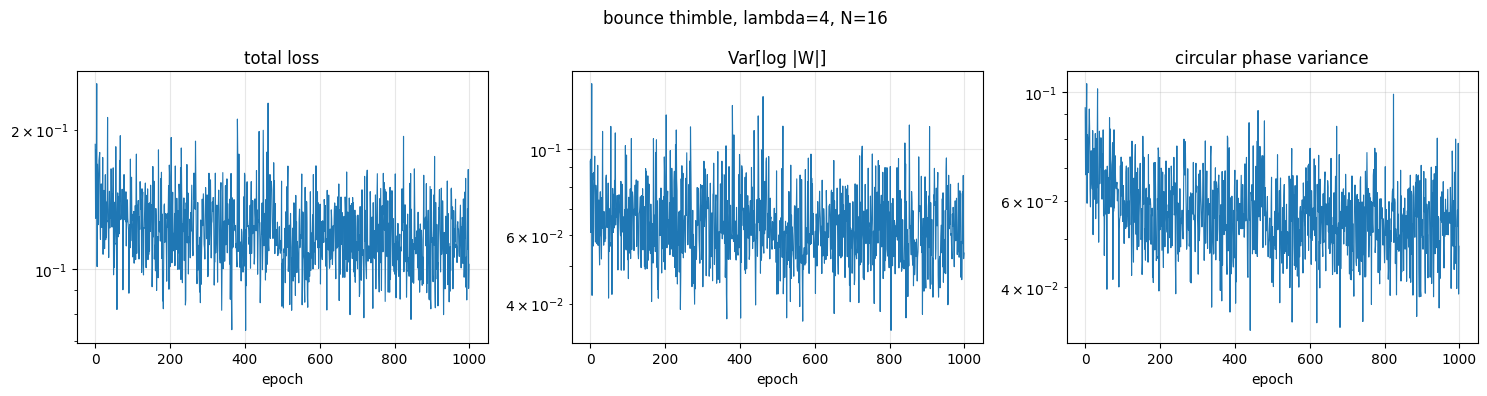

Saved all outputs to C:\xampp1\Quantum\runs\20260915_144540_MU_multithimble_lambda4_N16
Refreshed aggregate CSV: C:\xampp1\Quantum\runs\MU_multithimble_all_results.csv


In [9]:
for label, result in trained.items():
    torch.save(
        {
            "state_dict": result["model"].state_dict(),
            "saddle": result["saddle"],
            "lambda": LAMBDA,
            "N": N,
            "seed": result["seed"],
        },
        run_dir / f"{label}_model.pt",
    )

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for axis, key, title in zip(
        axes,
        ("total", "logmag", "phase"),
        ("total loss", "Var[log |W|]", "circular phase variance"),
    ):
        axis.semilogy(np.maximum(result["history"][key], 1e-18), lw=0.8)
        axis.set_title(title)
        axis.set_xlabel("epoch")
        axis.grid(alpha=0.3)
    fig.suptitle(f"{label} thimble, lambda={LAMBDA}, N={N}")
    fig.tight_layout()
    fig.savefig(run_dir / f"{label}_loss.png", dpi=150, bbox_inches="tight")
    plt.show()

np.savez(
    run_dir / "bounce_saddle.npz",
    x=bounce_saddle,
    action=action_np(bounce_saddle),
    hessian=hessian_np(bounce_saddle),
)

summary = {
    "lambda": LAMBDA,
    "N": N,
    "decomposition": "K_physical = K_trivial + 2*K_bounce",
    "K_trivial": [K_trivial.real, K_trivial.imag],
    "K_bounce": [K_bounce.real, K_bounce.imag],
    "K_combined": [K_combined.real, K_combined.imag],
    "K_reference": [reference.real, reference.imag],
    "single_thimble_relative_error": single_thimble_error,
    "combined_relative_error": combined_error,
    "combined_stderr": combined_stderr,
    "settings": {
        "rank": RANK, "epochs_per_saddle": EPOCHS, "batch": BATCH,
        "N_mc_per_saddle": N_MC, "learning_rate": LEARNING_RATE, "seed": SEED,
        "device": str(DEVICE), "quick_test": QUICK_TEST,
    },
    "individual": {
        label: {
            "K": [result["K"].real, result["K"].imag],
            "stderr": result["stderr"], "ESS_over_N": result["ESS"],
            "block_scatter": result["block_scatter"],
            "final_loss": result["history"]["total"][-1],
            "seconds": result["seconds"],
        }
        for label, result in trained.items()
    },
}

with (run_dir / "results.json").open("w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2)
with (run_dir / "results.csv").open("w", newline="", encoding="utf-8") as handle:
    writer = csv.writer(handle)
    writer.writerow([
        "lambda", "N", "K_trivial_re", "K_trivial_im", "K_bounce_re", "K_bounce_im",
        "K_physical_re", "K_physical_im", "K_reference_re", "K_reference_im",
        "single_relative_error", "corrected_relative_error", "combined_stderr",
        "trivial_ESS_over_N", "bounce_ESS_over_N",
    ])
    writer.writerow([
        LAMBDA, N, K_trivial.real, K_trivial.imag, K_bounce.real, K_bounce.imag,
        K_combined.real, K_combined.imag, reference.real, reference.imag,
        single_thimble_error, combined_error, combined_stderr,
        trained["trivial"]["ESS"], trained["bounce"]["ESS"],
    ])

# Refresh one aggregate CSV after every completed lambda run.  The newest result
# for each (lambda, N) wins, so rerunning a coupling does not create duplicates.
aggregate_path = Path("runs") / "MU_multithimble_all_results.csv"
latest = {}
for result_path in Path("runs").glob("*_MU_multithimble_lambda*_N*/results.json"):
    with result_path.open("r", encoding="utf-8") as handle:
        payload = json.load(handle)
    key = (float(payload["lambda"]), int(payload["N"]))
    if key not in latest or result_path.parent.name > latest[key][0].parent.name:
        latest[key] = (result_path, payload)

aggregate_columns = [
    "lambda", "N", "run_directory",
    "K_trivial_re", "K_trivial_im", "abs_K_trivial",
    "K_bounce_re", "K_bounce_im", "abs_K_bounce",
    "K_actual_re", "K_actual_im", "abs_K_actual",
    "K_reference_re", "K_reference_im", "abs_K_reference",
    "relative_complex_error", "combined_stderr",
    "trivial_ESS_over_N", "bounce_ESS_over_N",
    "epochs_per_saddle", "N_mc_per_saddle", "status",
]
with aggregate_path.open("w", newline="", encoding="utf-8") as handle:
    writer = csv.DictWriter(handle, fieldnames=aggregate_columns)
    writer.writeheader()
    for key in sorted(latest):
        result_path, payload = latest[key]
        k0 = complex(*payload["K_trivial"])
        kb = complex(*payload["K_bounce"])
        ka = complex(*payload["K_combined"])
        kr = complex(*payload["K_reference"])
        relative_error = float(payload["combined_relative_error"])
        writer.writerow({
            "lambda": payload["lambda"], "N": payload["N"],
            "run_directory": str(result_path.parent),
            "K_trivial_re": k0.real, "K_trivial_im": k0.imag,
            "abs_K_trivial": abs(k0),
            "K_bounce_re": kb.real, "K_bounce_im": kb.imag,
            "abs_K_bounce": abs(kb),
            "K_actual_re": ka.real, "K_actual_im": ka.imag,
            "abs_K_actual": abs(ka),
            "K_reference_re": kr.real, "K_reference_im": kr.imag,
            "abs_K_reference": abs(kr),
            "relative_complex_error": relative_error,
            "combined_stderr": payload["combined_stderr"],
            "trivial_ESS_over_N": payload["individual"]["trivial"]["ESS_over_N"],
            "bounce_ESS_over_N": payload["individual"]["bounce"]["ESS_over_N"],
            "epochs_per_saddle": payload["settings"]["epochs_per_saddle"],
            "N_mc_per_saddle": payload["settings"]["N_mc_per_saddle"],
            "status": "PASS" if relative_error < 0.05 else "FAIL",
        })

report = f"""# Corrected MU result

- lambda: `{LAMBDA}`
- N: `{N}`
- decomposition: `K_physical = K_trivial + 2*K_bounce`
- K_trivial: `{K_trivial}`
- K_bounce: `{K_bounce}`
- K_physical: `{K_combined}`
- same-N deterministic reference: `{reference}`
- old one-thimble relative error: `{100*single_thimble_error:.6f}%`
- corrected relative error: `{100*combined_error:.6f}%`
- combined MC stderr: `{combined_stderr:.6e}`
"""
(run_dir / "results_summary.md").write_text(report, encoding="utf-8")

print(f"Saved all outputs to {run_dir.resolve()}")
print(f"Refreshed aggregate CSV: {aggregate_path.resolve()}")

## 9. Visual comparison and acceptance check

The complex-plane plot shows exactly what changed: the zero-saddle answer stays near the old
nearly harmonic value, while subtracting the nonzero parity pair moves it onto the
same-$N$ anharmonic reference.  A run is accepted only when the corrected complex relative
error is below 5%, both individual ESS values are finite, and MC block scatter is controlled.

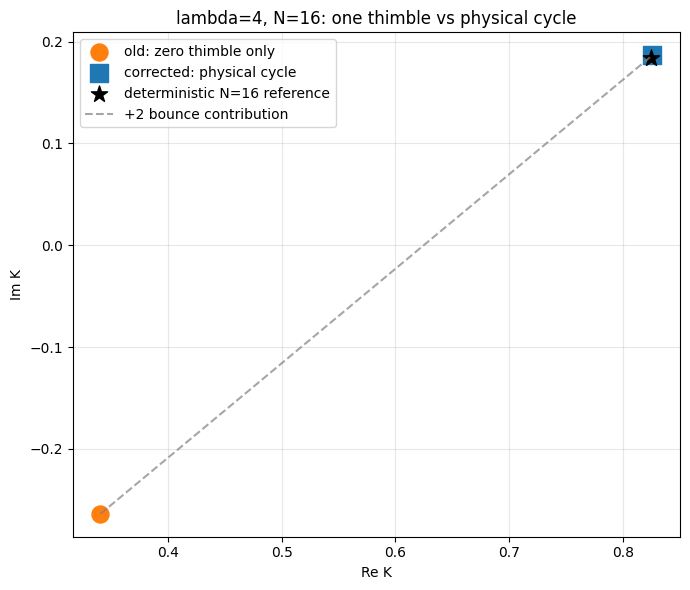

FINAL STATUS: PASS
lambda=4, N=16
K corrected = +0.8259942704+0.1865592010j
K reference = +0.8243744616+0.1842153864j
relative complex error = 0.3373%
old one-thimble error  = 78.0549%
trivial/bounce ESS     = 0.99058 / 0.69945
outputs: C:\xampp1\Quantum\runs\20260915_144540_MU_multithimble_lambda4_N16
comparison plot: C:\xampp1\Quantum\runs\20260915_144540_MU_multithimble_lambda4_N16\physical_cycle_comparison.png


In [10]:
fig, axis = plt.subplots(figsize=(7, 6))
points = [
    (K_trivial, "old: zero thimble only", "tab:orange", "o"),
    (K_combined, "corrected: physical cycle", "tab:blue", "s"),
    (reference, "deterministic N=16 reference", "black", "*"),
]
for value, label, color, marker in points:
    axis.scatter(value.real, value.imag, s=150, color=color, marker=marker, label=label)
axis.plot(
    [K_trivial.real, K_combined.real],
    [K_trivial.imag, K_combined.imag],
    "--", color="grey", alpha=0.7, label="+2 bounce contribution",
)
axis.set_xlabel("Re K")
axis.set_ylabel("Im K")
axis.set_title(f"lambda={LAMBDA}, N={N}: one thimble vs physical cycle")
axis.grid(alpha=0.3)
axis.legend()
fig.tight_layout()
comparison_path = run_dir / "physical_cycle_comparison.png"
fig.savefig(comparison_path, dpi=160, bbox_inches="tight")
plt.show()

finite_ess = np.isfinite(trained["trivial"]["ESS"]) and np.isfinite(trained["bounce"]["ESS"])
blocks_ok = all(
    result["block_scatter"] < max(5.0 * result["stderr"], 0.01 * abs(result["K"]))
    for result in trained.values()
)
passed = combined_error < 0.05 and finite_ess and blocks_ok and not QUICK_TEST
status = "PASS" if passed else ("QUICK_TEST_ONLY" if QUICK_TEST else "FAIL")

print("=" * 84)
print(f"FINAL STATUS: {status}")
print(f"lambda={LAMBDA}, N={N}")
print(f"K corrected = {K_combined:+.10f}")
print(f"K reference = {reference:+.10f}")
print(f"relative complex error = {100*combined_error:.4f}%")
print(f"old one-thimble error  = {100*single_thimble_error:.4f}%")
print(f"trivial/bounce ESS     = {trained['trivial']['ESS']:.5f} / {trained['bounce']['ESS']:.5f}")
print(f"outputs: {run_dir.resolve()}")
print(f"comparison plot: {comparison_path.resolve()}")